# Raw Data Analysis: EMG

## Packages

In [1]:
import pandas as pd 
import numpy as np
from scipy import stats
from scipy.fftpack import fft
from scipy import signal

import os, sys
import glob
#
import mne
# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots


import plotly.io as pio
pio.renderers.default = 'iframe'


processing_source_path = os.path.abspath('./../../Processing/')
if(processing_source_path not in sys.path):
    sys.path.append(processing_source_path)
import ProcessingPipeline as pp


processing_source_path = os.path.abspath('./../../Utils/')
if(processing_source_path not in sys.path):
    sys.path.append(processing_source_path)
import ProcessingPipeline as pp
import utils as utils 

from utils import Plot_Data as PLD



## Load the Data

### Dataset params

In [2]:
#2034.179688
#2031.746003
params={
    'dataset_path':'',
    'h5_file_path_train':'',
    'h5_file_path_test':'',
    'channels': '',
    'sampling_frequency':2034.179688,
    'extracted_frequencies': [4,500],
    'num_emg_channels': 64,
    'features_type': ['raw'],
    'preprocessing': ['HighPassFilter','LowPassFilter'],
    'num_classes':  7,
    'Grip_Patterns': [ "Rest", "Power Grip", "Tripod Grip", "Pinch", "Point", "Open Hand", "Key Grip", "Hook Grip"]
}

### Load SSVEP signal from csv file

In [3]:
sub_path='record_examples/sub03/2_csv/'

files=glob.glob(sub_path+f'*.csv')
files.sort()
for idx,file in enumerate(files):
    print(f'{idx}: {file}')

0: record_examples/sub03/2_csv/1_acq_dezotti_pinca_bidigital_2024-05-03_13-42-49.csv
1: record_examples/sub03/2_csv/2_acq_dezotti_pinca_tridigital_2024-05-03_13-45-47.csv
2: record_examples/sub03/2_csv/3_acq_dezotti_mao_fechada_2024-05-03_13-51-33.csv
3: record_examples/sub03/2_csv/4_acq_dezotti_gancho_2024-05-03_13-54-01.csv
4: record_examples/sub03/2_csv/5_acq_dezotti_mao_aberta_2024-05-03_13-48-06.csv
5: record_examples/sub03/2_csv/6_acq_dezotti_indicador_2024-05-03_13-56-28.csv


### load csv file of SSVEP signals

In [4]:
# load csv file of SSVEP signals
file_csv=files[1]
print("read the file:",file_csv) 
emg_data_df=pd.read_csv(file_csv)

read the file: record_examples/sub03/2_csv/2_acq_dezotti_pinca_tridigital_2024-05-03_13-45-47.csv


### Print data info

In [5]:
#Remove NAN values
#emg_data_df.iloc[:,:]=np.nan_to_num(emg_data_df.values)
n_samples,n_channels=emg_data_df.shape
print('EMGdata shape (samples, channels):',emg_data_df.shape)

# Get the time, time sample rate and max experiment time.
Ts= 1/params['sampling_frequency'] # time sample

print('frequency sample (Fs):', params['sampling_frequency'])
print('time sample (Ts):', Ts)
print('max time :',n_samples*Ts) 
print('EMG shape (samples,chaneels) :',emg_data_df.shape) 


EMGdata shape (samples, channels): (20072, 64)
frequency sample (Fs): 2034.179688
time sample (Ts): 0.0004915986556640909
max time : 9.867368216489634
EMG shape (samples,chaneels) : (20072, 64)


## Data preprocessing

### Apply processing steps

#### Downsample

In [6]:
import numpy as np
from scipy.signal import resample

def downsample_signal(data,old_Fs, new_Fs):
    downsample_factor = old_Fs//new_Fs
    # Calcular a nova taxa de amostragem
    fs_downsampled = params['sampling_frequency']/downsample_factor
    # Aplicar downsample no sinal EEG
    eeg_downsampled = resample(data, int(len(data) / downsample_factor))
    return eeg_downsampled

'''### uncomment to apply downsample version 1
downsample_freq=1000
emg_downsampled=downsample_signal(eeg_data_df.values,params['sampling_frequency'], downsample_freq)
emg_data_df = pd.DataFrame(eeg_downsampled,columns=eeg_data_df.columns.values)
params['sampling_frequency']=downsample_freq
print('New data shape (samples, channels):',eeg_data_df.shape)'''

"### uncomment to apply downsample version 1\ndownsample_freq=1000\nemg_downsampled=downsample_signal(eeg_data_df.values,params['sampling_frequency'], downsample_freq)\nemg_data_df = pd.DataFrame(eeg_downsampled,columns=eeg_data_df.columns.values)\nparams['sampling_frequency']=downsample_freq\nprint('New data shape (samples, channels):',eeg_data_df.shape)"

In [7]:
### uncomment to apply downsample version 2

'''downsample_processing = pp.ProcessingPipeline([
    # downsample
    pp.Downsample(params['sampling_frequency'],250),
])

emg_data_downsample=downsample_processing(emg_data_df.values.T).T
emg_data_df=pd.DataFrame(data=emg_data_downsample,columns=emg_data_df.columns)
params['sampling_frequency']=250
emg_data_df.shape'''

"downsample_processing = pp.ProcessingPipeline([\n    # downsample\n    pp.Downsample(params['sampling_frequency'],250),\n])\n\nemg_data_downsample=downsample_processing(emg_data_df.values.T).T\nemg_data_df=pd.DataFrame(data=emg_data_downsample,columns=emg_data_df.columns)\nparams['sampling_frequency']=250\nemg_data_df.shape"

#### Normalization

In [8]:
## uncomment the code below to use the normalization
#emg_data_df.loc[:,:]=data_processing(emg_data_df.values)
#rest_data_df.loc[:,:]=data_processing(rest_data_df.values)

#### DataFrame

In [9]:
print('Data shape:',emg_data_df.shape)
n_samples,n_channels=emg_data_df.shape
print(f'number of Samples: {n_samples}')
print(f'number of Channels: {n_channels}')

emg_data_df.head(3)

Data shape: (20072, 64)
number of Samples: 20072
number of Channels: 64


,Channel 0,Channel 1,Channel 2,Channel 3,Channel 4,Channel 5,Channel 6,Channel 7,Channel 8,Channel 9,...,Channel 54,Channel 55,Channel 56,Channel 57,Channel 58,Channel 59,Channel 60,Channel 61,Channel 62,Channel 63
0,0.2,0.2,0.2,-0.033418,-0.029446,0.008996,-0.009169,-0.033655,0.2,-0.045200,...,0.2,0.2,0.005994,-0.041428,-0.049248,0.2,0.2,0.2,0.2,0.2
1,0.2,0.2,0.2,-0.033328,-0.029485,0.009020,-0.009182,-0.033556,0.2,-0.045235,...,0.2,0.2,0.005964,-0.041415,-0.049255,0.2,0.2,0.2,0.2,0.2
2,0.2,0.2,0.2,-0.033362,-0.029522,0.009009,-0.009181,-0.033523,0.2,-0.045280,...,0.2,0.2,0.005917,-0.041459,-0.049333,0.2,0.2,0.2,0.2,0.2


In [10]:
# Descriptive Statistics of the Data
emg_data_df.describe()

,Channel 0,Channel 1,Channel 2,Channel 3,Channel 4,Channel 5,Channel 6,Channel 7,Channel 8,Channel 9,...,Channel 54,Channel 55,Channel 56,Channel 57,Channel 58,Channel 59,Channel 60,Channel 61,Channel 62,Channel 63
count,20072.0,20072.0,20072.0,20072.000000,20072.000000,20072.000000,20072.000000,20071.000000,20071.0,20071.000000,...,20071.0,20071.0,20071.000000,20071.000000,20071.000000,20071.0,20071.0,20071.0,20071.0,20071.0
mean,0.2,0.2,0.2,-0.033443,-0.030649,0.008508,-0.009130,-0.034261,0.2,-0.046447,...,0.2,0.2,0.005297,-0.041800,-0.049254,0.2,0.2,0.2,0.2,0.2
std,0.0,0.0,0.0,0.000352,0.000398,0.000289,0.000380,0.000299,0.0,0.000437,...,0.0,0.0,0.000520,0.000347,0.000376,0.0,0.0,0.0,0.0,0.0
min,0.2,0.2,0.2,-0.034814,-0.032110,0.007336,-0.010508,-0.035367,0.2,-0.048036,...,0.2,0.2,0.003240,-0.043075,-0.050569,0.2,0.2,0.2,0.2,0.2
25%,0.2,0.2,0.2,-0.033677,-0.030920,0.008316,-0.009383,-0.034465,0.2,-0.046754,...,0.2,0.2,0.004963,-0.042039,-0.049511,0.2,0.2,0.2,0.2,0.2
50%,0.2,0.2,0.2,-0.033445,-0.030658,0.008514,-0.009127,-0.034259,0.2,-0.046456,...,0.2,0.2,0.005305,-0.041799,-0.049256,0.2,0.2,0.2,0.2,0.2
75%,0.2,0.2,0.2,-0.033213,-0.030370,0.008702,-0.008885,-0.034059,0.2,-0.046125,...,0.2,0.2,0.005644,-0.041560,-0.048998,0.2,0.2,0.2,0.2,0.2
max,0.2,0.2,0.2,-0.032310,-0.029360,0.009508,-0.000000,-0.032984,0.2,-0.045163,...,0.2,0.2,0.007388,-0.040349,-0.047875,0.2,0.2,0.2,0.2,0.2


#### Get Data Values in array

##### Getting data array

In [11]:
# Get matrix values from dataframe 
emg_data_original= np.nan_to_num(emg_data_df.values)
emg_data = emg_data_original.copy()
emg_data_original.shape

(20072, 64)

#### Cut the data

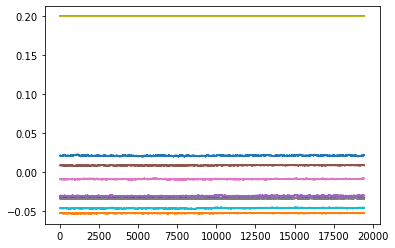

In [12]:
cut= True
#cut= False
if cut:
    # Selecting only the SSVEP stimultation interval 
    Nit=len(emg_data)
    Ts=1/params['sampling_frequency']
    T=np.arange(0,(Nit*Ts),Ts)

    t_min = 0.3#10
    t_max = T[-1]
    
    
    t_min =0.3#9
    t_max =T[-1]
    plt.plot(emg_data[np.where(T>=t_min)[0][0]:np.where(T>=t_max)[0][0],:12])
    plt.show()

    emg_data=emg_data[np.where(T>=t_min)[0][0]:np.where(T>=t_max)[0][0],:]

    cut=False
else:
    pass


In [13]:
emg_data_original=emg_data

### Filter

In [14]:
data_processing = pp.ProcessingPipeline([
     pp.NormMinMax(axis=0,minimum=0, maximum=1),  
])

filter_processing = pp.ProcessingPipeline([
    
    # band pass
    pp.HighPassFilter(10, params['sampling_frequency'], 3),
    pp.LowPassFilter(450, params['sampling_frequency'], 3),
    pp.NotchFilter(60,60.0,params['sampling_frequency']),
    pp.NotchFilter(120,60.0,params['sampling_frequency'])
    #pp.BandPassFilter(4,100, params['sampling_frequency'], 3),## lee_2019 reference papaer
    #pp.BandStopFilter(58, 63, params['sampling_frequency'], 3),
    #pp.ChebyshevFilter(4,57,params['sampling_frequency'],3,2),
    #pp.BandStopFilter(58, 63, params['sampling_frequency'], 3),

    #pp.ButterworthNotchFilter(60,params['sampling_frequency'],3) 
]) 


emg_preprocessing = pp.ProcessingPipeline([
    #pp.SampleTrimmer(axis=1, front=500, back=1),
    pp.Retification(),
    pp.EMGTKE(),
    pp.MAFilter(31),
    pp.NormMinMax(1,0,1)
])

In [15]:
n_channels

64

## Get raw files in csv

In [16]:
import csv
import os
def save_CSV(csv_name, n_channels, data):
    with open(csv_name, 'w', newline='', encoding='utf-8') as csv_file:
                writer = csv.writer(csv_file, delimiter=',', quotechar='|',quoting=csv.QUOTE_MINIMAL)
                writer.writerow([f'Channel {i}' for i in range(n_channels)])
                for datas in data.tolist():
                    writer.writerow(datas)

In [17]:
rest_trial=0
for idx,file in enumerate(files):
    
    eeg_data_df=pd.read_csv(file)

    # remove nan numbers
    emg_data= np.nan_to_num(eeg_data_df.values)
    n_samples, n_channels = emg_data.shape
    
    #emg_data=filter_processing(emg_data.T).T
    
    # segment the interval of each task frequency 
    n_init= [0]
    n_final=[0]
    time_per_trial=5 # time used in each trial .

    for n_trial in (np.arange(time_per_trial,(n_samples*Ts),time_per_trial)//Ts):
        n_init+=[int(n_final[-1])]
        n_final+= [int(n_trial)]

    n_init=n_init[1:]
    n_final=n_final[1:]
    print(f'{n_init}: {n_final}')

    for trial in range(len(n_final)):
        #print(trial, len(emg_data[n_init[trial]:n_final[trial],:])*Ts)

        if trial%2 ==1:
            csv_name=f'S2-G{0}-R{rest_trial}-R_'+file[-23:]
            rest_trial+=1
        else:
            csv_name=f'S2-G{idx+1}-R{(trial//2) +1}-G_'+file[-23:]

        print(csv_name)
        save_folder='record_examples/sub03/'
        save_CSV(save_folder+csv_name, n_channels, emg_data[n_init[trial]:n_final[trial],:])

[0, 10170]: [10170, 20341]
S2-G1-R1-G_2024-05-03_13-42-49.csv
S2-G0-R0-R_2024-05-03_13-42-49.csv
[0]: [10170]
S2-G2-R1-G_2024-05-03_13-45-47.csv
[0]: [10170]
S2-G3-R1-G_2024-05-03_13-51-33.csv
[0, 10170]: [10170, 20341]
S2-G4-R1-G_2024-05-03_13-54-01.csv
S2-G0-R1-R_2024-05-03_13-54-01.csv
[0, 10170]: [10170, 20341]
S2-G5-R1-G_2024-05-03_13-48-06.csv
S2-G0-R2-R_2024-05-03_13-48-06.csv
[0, 10170]: [10170, 20341]
S2-G6-R1-G_2024-05-03_13-56-28.csv
S2-G0-R3-R_2024-05-03_13-56-28.csv
